# GDGoC UGM Academic Hacker 2026/2027 — Prediksi Diagnosis Pasien (4 Kelas)

**Tugas:** memprediksi `target_class` ∈ {`viral_sinusitis`, `viral_pharyngitis`, `acute_bronchitis`, `strep_pharyngitis`}
dari data rekam medis relasional (multi-CSV). **Metrik:** Macro-F1.

# Load Data

In [1]:
import numpy as np

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import classification_report, f1_score
from sklearn.model_selection import StratifiedKFold

DATA = Path("../GDGoC-2026")
TRIASE = DATA / "Triase" / "Triase"
RIWAYAT_DIR = DATA / "Riwayat Medis" / "Riwayat Medis"
KEY, PASIEN = "encounter_id", "patient_id"
TARGET, ID = "target_class", "sample_id"
SEED, N_FOLD, N_REPEAT = 42, 5, 3

GRUP = {}

for folder in (DATA, TRIASE, RIWAYAT_DIR):          # gagal cepat jika path salah
    assert folder.is_dir(), f"Folder tidak ditemukan: {folder.resolve()}"
print("Data dibaca dari:", DATA.resolve())

Data dibaca dari: C:\INAH-MINE\GEMASTIK-XIX\GDGoC-2026


In [2]:
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
waktu = pd.read_csv(DATA / "index_encounters.csv")
patients = pd.read_csv(DATA / "patients.csv")

print(f"train {train.shape} | test {test.shape} | index_encounters {waktu.shape} | patients {patients.shape}")
print("kolom train:", list(train.columns))
print("kolom test :", list(test.columns))

train (3600, 4) | test (1400, 3) | index_encounters (5000, 3) | patients (5000, 10)
kolom train: ['sample_id', 'patient_id', 'encounter_id', 'target_class']
kolom test : ['sample_id', 'patient_id', 'encounter_id']


In [3]:
import numpy as np

def norm(s):
    """teks → huruf kecil, simbol jadi spasi (menyatukan 'Cough / productive' dan 'cough productive')."""
    return s.astype(str).str.lower().str.replace(r"[^a-z0-9]+", " ", regex=True).str.strip()

def angka(s):
    """'USD 1,234' / '$1,234' / '115.6k' / '28,02' → float. Koma = ribuan kalau diikuti 3 digit, selain itu desimal."""
    s = s.astype(str).str.lower().str.replace(r"usd|\$|\s", "", regex=True)
    kali = np.where(s.str.endswith("k"), 1000, 1)
    s = s.str.rstrip("k").str.replace(r",(?=\d{3}(\D|$))", "", regex=True).str.replace(",", ".")
    return pd.to_numeric(s, errors="coerce") * kali


assert angka(pd.Series(["USD 1,234", "$34,487", "115.6k", "28,02", "0,9", "12679.0", None])).round(2).tolist()[:6] == \
    [1234, 34487, 115600, 28.02, 0.9, 12679]

# EDA

## Overall

                   jumlah  persen
target_class                     
viral_sinusitis      1480    41.1
viral_pharyngitis     985    27.4
acute_bronchitis      940    26.1
strep_pharyngitis     195     5.4
rasio kelas terbanyak : tersedikit = 7.6
macro-F1 jika selalu menebak kelas terbanyak: 0.146


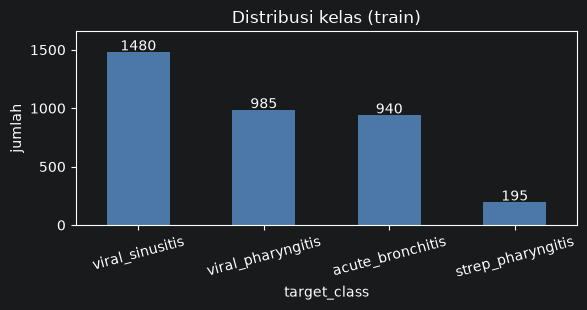

In [4]:
vc = train[TARGET].value_counts()
print(pd.DataFrame({"jumlah": vc, "persen": (vc / len(train) * 100).round(1)}))
print("rasio kelas terbanyak : tersedikit =", round(vc.max() / vc.min(), 1))

tebak_mayoritas = np.full(len(train), vc.idxmax())
print("macro-F1 jika selalu menebak kelas terbanyak:",
      round(f1_score(train[TARGET], tebak_mayoritas, average="macro"), 3))

ax = vc.plot.bar(color="#4C78A8", figsize=(6, 3.2), rot=15)
ax.set_title("Distribusi kelas (train)"); ax.set_ylabel("jumlah"); ax.set_ylim(0, vc.max() * 1.12)
for i, v in enumerate(vc.values):
    ax.text(i, v + 15, f"{v}", ha="center")
plt.tight_layout(); plt.show()

In [5]:
inventaris = []
for folder in (DATA, TRIASE, RIWAYAT_DIR):
    for f in sorted(folder.glob("*.csv")):
        d = pd.read_csv(f)
        inventaris.append({
            "file": str(f.relative_to(DATA)),
            "baris": len(d),
            "n_encounter": d[KEY].nunique() if KEY in d.columns else None,
            "n_pasien": d[PASIEN].nunique() if PASIEN in d.columns else None,
            "kosong_maks_%": round(d.isna().mean().max() * 100, 1),
            "kolom": ", ".join(d.columns),
        })
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 220)
inventaris = pd.DataFrame(inventaris)
inventaris

,file,baris,n_encounter,n_pasien,kosong_maks_%,kolom
0,DATA_DICTIONARY.csv,87,NaN,NaN,0.0,"file, column, semantic_type, model_role, notes"
1,index_encounters.csv,5000,5000.0,5000.0,0.0,"patient_id, encounter_id, prediction_time"
2,patients.csv,5000,NaN,5000.0,42.3,"patient_id, age_at_visit, gender, race, ethnicity, city, county, state, income_at_visi..."
3,sample_submission.csv,1400,NaN,NaN,100.0,"sample_id, target_class"
4,test.csv,1400,1400.0,1400.0,0.0,"sample_id, patient_id, encounter_id"
5,train.csv,3600,3600.0,3600.0,0.0,"sample_id, patient_id, encounter_id, target_class"
6,Triase\Triase\presenting_complaints.csv,5000,5000.0,5000.0,0.0,"patient_id, encounter_id, presenting_complaints_text"
7,Triase\Triase\triage_symptom_severity.csv,16594,4961.0,4961.0,4.6,"patient_id, encounter_id, observed_at, symptom_concept, severity_score"
8,Triase\Triase\triage_symptoms.csv,19065,5000.0,5000.0,0.0,"patient_id, encounter_id, observed_at, symptom_concept"
9,Triase\Triase\triage_vitals.csv,30000,5000.0,5000.0,11.1,"patient_id, encounter_id, measured_at, vital_name, value, unit"


In [6]:
RIWAYAT = {                                         # tabel riwayat -> nama kolom tanggalnya
    "conditions": "recorded_at", "medications": "recorded_at", "procedures": "recorded_at",
    "immunizations": "recorded_at", "allergies": "recorded_at", "observations": "observed_at",
    "previous_encounter": "history_start",
}

## Audit Patients

In [7]:
patients.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   patient_id        5000 non-null   object 
 1   age_at_visit      4940 non-null   float64
 2   gender            5000 non-null   object 
 3   race              5000 non-null   object 
 4   ethnicity         4856 non-null   object 
 5   city              2884 non-null   object 
 6   county            4492 non-null   object 
 7   state             5000 non-null   object 
 8   income_at_visit   4545 non-null   object 
 9   marital_at_visit  3193 non-null   object 
dtypes: float64(1), object(9)
memory usage: 390.8+ KB


In [8]:
AUDIT = []

# umur
umur = patients["age_at_visit"]
n_999 = int((umur == 999).sum())
n_luar = int((umur.notna() & (umur != 999) & ~umur.between(0, 120)).sum())   # nilai tak masuk akal selain 999
print(f"umur: kode 999 = {n_999} | di luar 0-120 selain 999 = {n_luar} | kosong = {umur.isna().sum()}")
print(umur[umur.between(0, 120)].describe().round(1).to_string())
AUDIT.append(("umur kode 999 / di luar 0-120", n_999 + n_luar, "diganti NaN"))

umur: kode 999 = 19 | di luar 0-120 selain 999 = 0 | kosong = 60
count    4921.0
mean       38.8
std        21.4
min         0.0
25%        20.5
50%        38.3
75%        56.0
max        90.0


In [9]:
# income: format

inc = patients["income_at_visit"].astype("string").str.strip()
jenis = pd.Series("lainnya", index=inc.index)
POLA = {
    "angka polos (12679.0)": r"\d+(\.\d+)?",
    "singkatan k (115.6k)": r"(?i)[\d.,]+k",
    "dolar ($34,487)": r"\$[\d,.]+",
    "USD (USD 1,234)": r"(?i)usd\s*[\d,.]+",
}
for nama, pola in POLA.items():
    jenis[inc.str.fullmatch(pola).fillna(False).astype(bool)] = nama
jenis[inc.isna()] = "kosong"
print("\nformat income:")
print(pd.DataFrame({"jumlah": jenis.value_counts(), "contoh": inc.groupby(jenis).first()}).to_string())
n_campur = int((~jenis.isin(["kosong", "angka polos (12679.0)"])).sum())
AUDIT.append(("income berformat non-polos (USD/$/k/lainnya)", n_campur, "angka(): buang simbol, 'k' x1000, koma ribuan"))
AUDIT.append(("income kosong", int((jenis == "kosong").sum()), "dibiarkan NaN"))


format income:
                       jumlah       contoh
USD (USD 1,234)            71  USD 122,462
angka polos (12679.0)    3855     620511.0
dolar ($34,487)           232      $51,777
kosong                    455         <NA>
lainnya                   225       36,523
singkatan k (115.6k)      162         0.0k


In [10]:
# status nikah:
mar = patients["marital_at_visit"].dropna().astype(str)
print("\nmarital (mentah):", mar.value_counts().to_dict())
kata_penuh = mar[mar.str.len() > 1]                 # "Married", "Single", ... (bukan kode 1 huruf)
bentrok = kata_penuh.groupby(kata_penuh.str[0]).nunique()   # huruf awal yang dipakai >1 kata berbeda
print("huruf awal yang bentrok (>1 status berbeda):", bentrok[bentrok > 1].to_dict() or "tidak ada")




marital (mentah): {'M': 1852, 'S': 621, 'D': 455, 'W': 116, 'Married': 80, 'Divorced': 32, 'Single': 27, 'Widowed': 10}
huruf awal yang bentrok (>1 status berbeda): tidak ada


In [11]:
# kolom kategori
KAT = ["gender", "race", "ethnicity", "county"]
print("\nkardinalitas:", patients[KAT].nunique().to_dict())
for c in KAT:
    print(f"{c:10s}", patients[c].value_counts(dropna=False).head(5).to_dict())


kardinalitas: {'gender': 2, 'race': 6, 'ethnicity': 2, 'county': 58}
gender     {'F': 2645, 'M': 2355}
race       {'white': 4104, 'black': 431, 'asian': 326, 'other': 63, 'hawaiian': 47}
ethnicity  {'nonhispanic': 4332, 'hispanic': 524, nan: 144}
county     {'Middlesex County': 1065, 'Worcester County': 512, nan: 508, 'Suffolk County': 486, 'Essex County': 469}


## Audit Triase

In [12]:
v = pd.read_csv(TRIASE / "triage_vitals.csv")
n_enc = len(train) + len(test)                      # jumlah kunjungan seluruhnya
mentah = v["value"].astype(str)
n_koma_desimal = int(mentah.str.contains(r",\d{1,2}$").sum())    # '28,02' -> koma = desimal
n_koma_ambigu = int(mentah.str.contains(r",\d{3}$").sum())       # ',ddd' -> ribuan ATAU desimal 3 digit?
v["nilai"] = angka(v["value"])
n_gagal = int(v["nilai"].isna().sum() - v["value"].isna().sum()) # nilai ada, tetapi tidak terbaca angka
print(f"baris {len(v)} | kunjungan {v[KEY].nunique()} dari {n_enc} | koma desimal {n_koma_desimal} | koma ambigu {n_koma_ambigu} | gagal parse {n_gagal}")


baris 30000 | kunjungan 5000 dari 5000 | koma desimal 112 | koma ambigu 0 | gagal parse 0


In [13]:
# satuan beda skala: median satuan itu vs median vital itu (mis. 10,5 kPa vs 79 mmHg)
med_vital = v.groupby("vital_name")["nilai"].transform("median")
med_unit = v.groupby(["vital_name", "unit"])["nilai"].transform("median")
rasio = med_unit / med_vital
beda_skala = rasio.notna() & ~rasio.between(0.5, 2)
dobel = int(v.duplicated([KEY, "vital_name"], keep=False).sum())  # baris yang berbagi (kunjungan, vital) yang sama

# Menampilkan hasil
print(f"Jumlah data dengan perbedaan skala: {beda_skala.sum()}")
print(f"Jumlah baris yang terindikasi duplikat: {dobel}")



Jumlah data dengan perbedaan skala: 1049
Jumlah baris yang terindikasi duplikat: 0


In [14]:
ringkasan = (
    v.assign(
        median_unit=med_unit,
        median_vital=med_vital,
        rasio=rasio,
        beda_skala=beda_skala
    )
    .groupby(["vital_name", "unit"])
    .agg(
        jumlah_data=("nilai", "count"),
        median_unit=("median_unit", "first"),
        median_vital=("median_vital", "first"),
        rasio=("rasio", "first"),
        beda_skala=("beda_skala", "first")
    )
    .reset_index()
)

print(ringkasan.to_string(index=False))

      vital_name        unit  jumlah_data  median_unit  median_vital    rasio  beda_skala
             BMI       kg/m2         3114       27.790         27.79 1.000000       False
    Diastolic BP         kPa          315       10.530         78.00 0.135000        True
    Diastolic BP        mmHg         4407       79.000         78.00 1.012821       False
      Heart rate        /min         4031       80.000         80.00 1.000000       False
      Heart rate   beats/min          661       80.000         80.00 1.000000       False
Respiratory rate        /min         4057       14.000         14.00 1.000000       False
Respiratory rate breaths/min          656       14.000         14.00 1.000000       False
            SpO2           %         4275       94.000         94.00 1.000000       False
            SpO2    fraction          427        0.940         94.00 0.010000        True
     Systolic BP         kPa          298       15.855        116.04 0.136634        True
     Systo

## Audit Gejala

In [15]:
g = pd.read_csv(TRIASE / "triage_symptoms.csv")
g["nama"] = norm(g["symptom_concept"])              # samakan huruf besar/kecil & simbol
n_mentah, n_norm = g["symptom_concept"].nunique(), g["nama"].nunique()
per_kunjungan = g.groupby(KEY).size()               # berapa baris gejala tiap kunjungan
n_tanpa = n_enc - per_kunjungan.size                # kunjungan tanpa satu pun baris gejala
print(f"nama gejala: mentah {n_mentah} -> setelah norm() {n_norm} | baris {len(g)} | kunjungan tanpa gejala {n_tanpa}")
print("gejala per kunjungan:", per_kunjungan.describe().round(2).to_dict())
print("\n60 nama gejala teratas (setelah norm):")
print(g["nama"].value_counts().head(60).to_string())

sev = pd.read_csv(TRIASE / "triage_symptom_severity.csv")
print("\nseverity_score:", sev["severity_score"].describe().round(2).to_dict())
AUDIT.append(("variasi penulisan gejala (mentah - setelah norm)", n_mentah - n_norm, "norm() lalu kamus sinonim"))

nama gejala: mentah 118 -> setelah norm() 70 | baris 19065 | kunjungan tanpa gejala 0
gejala per kunjungan: {'count': 5000.0, 'mean': 3.81, 'std': 1.79, 'min': 1.0, '25%': 3.0, '50%': 4.0, '75%': 5.0, 'max': 12.0}

60 nama gejala teratas (setelah norm):
nama
throat symptoms                   1793
head and facial symptoms          1542
systemic symptoms                 1464
cough                             1345
nasal symptoms                    1250
fever                             1203
respiratory secretions            1151
dyspnea wheeze                     615
painful swallowing                 437
throat pain                        426
throat discomfort                  417
sore throat                        398
persistent cough                   360
cough symptom                      344
coughing                           341
cough productive                   315
body malaise                       315
nasal congestion                   311
nasal complaints                   297


## Kebocoran dan Kemiripan

In [16]:
semua = pd.concat([train.assign(bagian="train"), test.assign(bagian="test")], ignore_index=True)
semua = semua.merge(waktu[[KEY, "prediction_time"]], on=KEY, how="left")
semua["prediction_time"] = pd.to_datetime(semua["prediction_time"], utc=True)

print("pasien di train DAN test   :", len(set(train[PASIEN]) & set(test[PASIEN])))
print("kunjungan di train DAN test:", len(set(train[KEY]) & set(test[KEY])))
print("rentang waktu prediksi per bagian (train vs test harus mirip):")
print(semua.groupby("bagian")["prediction_time"].agg(["min", "max"]).to_string())

hasil = []
for nama, kol in RIWAYAT.items():                   # tiap tabel riwayat: adakah catatan SETELAH waktu prediksi?
    t = pd.read_csv(RIWAYAT_DIR / f"{nama}.csv")
    n_awal = len(t)
    t["_t"] = pd.to_datetime(t[kol], utc=True, format="mixed")
    t = t.merge(semua[[PASIEN, "prediction_time"]], on=PASIEN, how="inner")   # hanya pasien yang menjadi sampel
    hasil.append({"tabel": nama, "baris": n_awal, "pasien_di_luar_sampel": n_awal - len(t),
                  "tanggal_kosong": int(t["_t"].isna().sum()),
                  "sesudah_waktu_prediksi": int((t["_t"] >= t["prediction_time"]).sum())})
hasil = pd.DataFrame(hasil)
print("\nriwayat vs waktu prediksi:")
print(hasil.to_string(index=False))
AUDIT.append(("riwayat sesudah waktu prediksi (kebocoran waktu)", int(hasil["sesudah_waktu_prediksi"].sum()), "difilter: hanya t < prediction_time"))

pd.DataFrame(AUDIT, columns=["temuan", "jumlah", "penanganan"])     # tabel temuan kualitas data untuk write-up

pasien di train DAN test   : 0
kunjungan di train DAN test: 0
rentang waktu prediksi per bagian (train vs test harus mirip):
                             min                       max
bagian                                                    
test   2024-03-27 07:16:35+00:00 2026-10-29 07:40:32+00:00
train  2024-05-22 20:17:27+00:00 2026-10-31 19:05:32+00:00

riwayat vs waktu prediksi:
             tabel  baris  pasien_di_luar_sampel  tanggal_kosong  sesudah_waktu_prediksi
        conditions   3583                      0               0                       0
       medications   3467                      0               0                       0
        procedures  17024                      0               0                       0
     immunizations   1802                      0               0                       0
         allergies      2                      0               0                       0
      observations  55648                      0               0             

,temuan,jumlah,penanganan
0,umur kode 999 / di luar 0-120,19,diganti NaN
1,income berformat non-polos (USD/$/k/lainnya),690,"angka(): buang simbol, 'k' x1000, koma ribuan"
2,income kosong,455,dibiarkan NaN
3,variasi penulisan gejala (mentah - setelah norm),48,norm() lalu kamus sinonim
4,riwayat sesudah waktu prediksi (kebocoran waktu),0,difilter: hanya t < prediction_time


# Preprosessing

## Menentukan Master Table

In [ ]:
# --- tabel utama ---

base = pd.concat([train, test], ignore_index=True)

waktu = pd.read_csv("../gdgoc-ugm-academic-hacker-2026/index_encounters.csv")
waktu["prediction_time"] = pd.to_datetime(waktu["prediction_time"], utc=True)
base = base.merge(waktu[[KEY, "prediction_time"]], on=KEY, how="left")
assert base[KEY].is_unique and base["prediction_time"].notna().all()


## Memastikan Pemetaannya 1-ke-1 dengan satu baris per pasien

In [ ]:
assert base[PASIEN].is_unique                          # 1 pasien = 1 baris sampel
assert patients[PASIEN].is_unique                      # tabel pasien: 1 pasien = 1 baris
assert not set(train[PASIEN]) & set(test[PASIEN])      # pasien yang sama tidak boleh ada di train DAN test
cek = index_enc.merge(base[[KEY, PASIEN]], on=KEY, suffixes=("_ie", "_base"))
assert (cek[PASIEN + "_ie"] == cek[PASIEN + "_base"]).all()   # encounter -> pasien konsisten di kedua tabel
print("sampel:", len(base), "| train:", base[TARGET].notna().sum(), "| test:", base[TARGET].isna().sum())


## Normalisasi Isi dari Data

In [ ]:
p = pd.read_csv("../gdgoc-ugm-academic-hacker-2026/patients.csv")
p["age"] = p["age_at_visit"].where(p["age_at_visit"].between(0, 120))   # 999 = kode kosong
p["income"] = angka(p["income_at_visit"])
p["marital"] = p["marital_at_visit"].str[0]                               # Married → M, Single → S
KATEGORI = ["gender", "race", "ethnicity", "marital", "county"]           # UBAH
feat = base.merge(p[[PASIEN, "age", "income"] + KATEGORI], on=PASIEN, how="left")
print(p[["age", "income"]].describe().round(1))